# EdgeFit — On-Device Activity Recognition: Analysis & Recommendation

**Business question:** Which model should EdgeFit ship to recognise user activities *directly on the wearable*, so that it works
reliably for **new customers** while fitting the device's compute, memory and battery budget?

**Decision criteria**, in order of importance:
1. **Quality for new users**: Macro F1 on people the model has never seen (every activity counts equally).
2. **Deployment footprint**: model size, compute per prediction, number of sensor features computed on the device.
3. **Explainability**: can product, QA and regulatory teams understand why an activity is predicted?

---

### Executive summary

| | Result |
|---|---|
| **Recommendation** | Logistic Regression on the full 561-feature set |
| **Quality on 6 unseen users** | Macro F1 **0.966**, accuracy **96.4 %**, per-user accuracy 91.9 %–99.5 % |
| **Footprint** | **25 KB** model, ~7,900 arithmetic operations per prediction (one prediction is needed every 1.28 s) |
| **Main residual error** | *sitting ↔ standing*: 58 of 82 errors |
| **Feature-light alternative** | 25 features (−95.5 %): Macro F1 0.897, ≈2.8× more errors; only for the most constrained hardware |
| **Key risk avoided** | A naive random-split evaluation would have reported Macro F1 0.984, understating real-world errors on new customers ≈3.6× |

The interactive version of this analysis is in the Streamlit app (`app.py`). The production pipeline that generates the app's
artifacts is `train.py`; this notebook follows the same steps and settings, so the predictive results match.

## 1. Setup

In [1]:
import os, sys, time, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn, lightgbm
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score

# Shared, tested building blocks from the production pipeline (train.py in this repository)
from train import (download_dataset, load, lr_pipeline, lgbm, rf, size_mb, latency_ms,
                   native_lr_latency_us, grouped_cv_f1, TEST_SUBJECTS, RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .3, "font.size": 10})
BLUE, AMBER, GREEN, GREY = "#2563EB", "#F59E0B", "#10B981", "#94A3B8"
np.random.seed(RANDOM_STATE)

# Set EDGEFIT_DATA_DIR to a local "UCI HAR Dataset" folder to skip the download
DATA_DIR = os.environ.get("EDGEFIT_DATA_DIR")
root = Path(DATA_DIR) if DATA_DIR else download_dataset(Path(".data"))
X, y, groups, feature_names, activities = load(root)
ACT = [a.replace("_", " ").title() for a in activities]
print(f"{X.shape[0]:,} sensor windows · {X.shape[1]} features · {len(np.unique(groups))} people · {len(ACT)} activities")

10,299 sensor windows · 561 features · 30 people · 6 activities


## 2. The data

The public **UCI Human Activity Recognition** dataset: 30 volunteers wore a smartphone on the waist while walking, climbing
stairs, sitting, standing and lying. The 50 Hz accelerometer and gyroscope signals were cut into **2.56-second windows with 50 %
overlap**, so a deployed device needs one prediction every **1.28 s**. Each window is described by 561 engineered features
(time- and frequency-domain statistics).

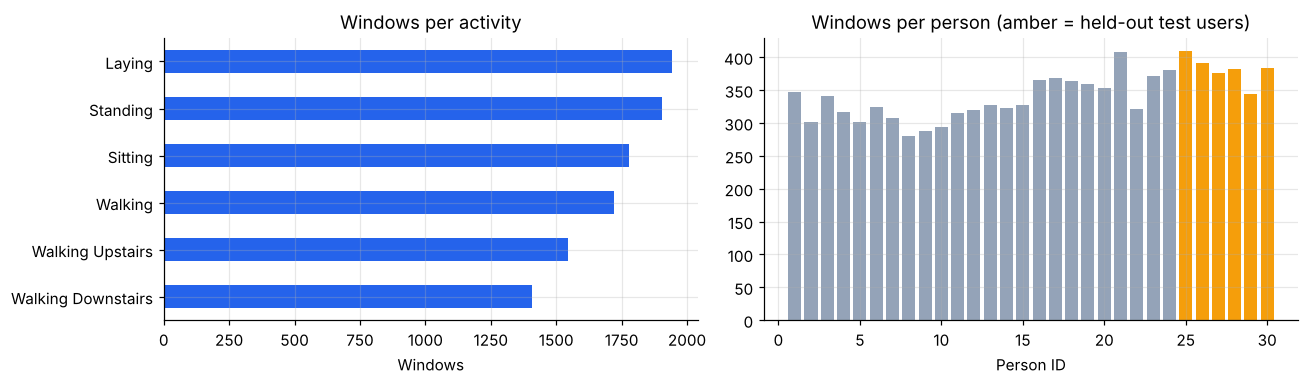

Missing values: 0 · class balance (largest/smallest): 1.38x


In [2]:
counts = pd.Series(y).map(dict(enumerate(ACT))).value_counts()
per_person = pd.Series(groups).value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
counts.sort_values().plot.barh(ax=ax[0], color=BLUE)
ax[0].set_title("Windows per activity"); ax[0].set_xlabel("Windows")
ax[1].bar(per_person.index, per_person.values, color=[AMBER if s in TEST_SUBJECTS else GREY for s in per_person.index])
ax[1].set_title("Windows per person (amber = held-out test users)"); ax[1].set_xlabel("Person ID")
plt.tight_layout(); plt.show()

print(f"Missing values: {int(np.isnan(X).sum())} · class balance (largest/smallest): {counts.max() / counts.min():.2f}x")

The data is clean (no missing values) and only mildly imbalanced, so Macro F1 and accuracy tell a similar story. Every person
contributes 280–410 windows, which matters for the next step.

## 3. Evaluating the way the product will be used

EdgeFit's model will be used by **new customers** who were never part of the training data. Windows from the same person are
highly similar, so if one person's windows appear in both the training and the evaluation data, the model is graded partly on
people it already knows. That is *data leakage*, and it makes the result look better than it will be in the field.

**Evaluation design:** persons 25–30 are held out completely as "new customers" and used exactly once at the end. All model
choices are made with **grouped cross-validation** on persons 1–24, where each fold validates on people not used for training.

The cost of getting this wrong, measured on the training persons:

In [3]:
test = np.isin(groups, TEST_SUBJECTS)
X_tr, y_tr, g_tr = X[~test], y[~test], groups[~test]
X_te, y_te, g_te = X[test], y[test], groups[test]
assert set(g_tr).isdisjoint(g_te)

cv_grouped = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
cv_random = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

f1_random = cross_val_score(lr_pipeline(), X_tr, y_tr, cv=cv_random, scoring="f1_macro")
f1_grouped = cross_val_score(lr_pipeline(), X_tr, y_tr, groups=g_tr, cv=cv_grouped, scoring="f1_macro")

leak = pd.DataFrame({"Evaluation": ["Random split (people mixed)", "Grouped by person (realistic)"],
                     "Macro F1": [f1_random.mean(), f1_grouped.mean()],
                     "± (fold std)": [f1_random.std(), f1_grouped.std()],
                     "Implied error rate": [1 - f1_random.mean(), 1 - f1_grouped.mean()]})
display(leak.style.format({"Macro F1": "{:.3f}", "± (fold std)": "{:.3f}", "Implied error rate": "{:.1%}"}).hide(axis="index"))
print(f"A random split understates the error rate on new people by about {(1 - f1_grouped.mean()) / (1 - f1_random.mean()):.1f}x.")

Evaluation,Macro F1,± (fold std),Implied error rate
Random split (people mixed),0.984,0.002,1.6%
Grouped by person (realistic),0.942,0.014,5.8%


A random split understates the error rate on new people by about 3.6x.


**Business takeaway:** a standard random split would promise ≈98 % quality, but new customers would actually see ≈94 % in
cross-validation, roughly **3.6× more errors than promised**. Every result below therefore uses person-level evaluation. The
fold-to-fold spread is also much larger when grouping by person, because people move differently; that variation is real and
has to be planned for.

## 4. Candidate models

Three model families with very different cost profiles, each tested with all 561 features and with only the 25 most important
features (ranked by Random Forest importance on the **training persons only**):

- **Logistic Regression**: linear, tiny, fully explainable;
- **LightGBM**: gradient-boosted trees, the usual strong choice for tabular data;
- **Random Forest**: bagged trees, robust but large.

In [4]:
t0 = time.time()
rf_full = rf().fit(X_tr, y_tr)
rf_time = time.time() - t0
ranking = np.argsort(rf_full.feature_importances_)[::-1]
top25 = ranking[:25]

candidates = {
    "Logistic Regression": (lr_pipeline, None),
    "Logistic Regression (top 25)": (lr_pipeline, top25),
    "LightGBM": (lgbm, None),
    "LightGBM (top 25)": (lgbm, top25),
    "Random Forest": (None, None),
    "Random Forest (top 25)": (rf, top25),
}

rows, models, preds = [], {}, {}
for name, (make, idx) in candidates.items():
    cols = slice(None) if idx is None else idx
    if name == "Random Forest":
        model, train_s = rf_full, rf_time
    else:
        t0 = time.time(); model = make().fit(X_tr[:, cols], y_tr); train_s = time.time() - t0
    p = model.predict(X_te[:, cols])
    single_ms, batch_ms = latency_ms(model, X_te[:1, cols], X_te[:1000, cols])
    rows.append({"Model": name, "Features": X_tr[:, cols].shape[1],
                 "Macro F1": f1_score(y_te, p, average="macro"), "Accuracy": accuracy_score(y_te, p),
                 "Size (KB)": size_mb(model) * 1024, "Latency/window (ms)": single_ms,
                 "Latency/1,000 windows (ms)": batch_ms, "Train time (s)": train_s})
    models[name], preds[name] = (model, idx), p

results = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results.style.format({"Macro F1": "{:.3f}", "Accuracy": "{:.1%}", "Size (KB)": "{:,.0f}",
                              "Latency/window (ms)": "{:.2f}", "Latency/1,000 windows (ms)": "{:.1f}",
                              "Train time (s)": "{:.1f}"})
        .highlight_max(subset=["Macro F1", "Accuracy"], color="#D1FAE5")
        .highlight_min(subset=["Size (KB)", "Latency/window (ms)"], color="#DBEAFE").hide(axis="index"))
print("Evaluated once on persons 25-30 (", len(y_te), "windows). Latency: median scikit-learn call on this machine's CPU.")

Model,Features,Macro F1,Accuracy,Size (KB),Latency/window (ms),"Latency/1,000 windows (ms)",Train time (s)
Logistic Regression,561,0.966,96.4%,25,0.27,1.6,1.4
LightGBM,561,0.943,94.1%,"1,778",0.90,100.8,79.1
Random Forest,561,0.927,92.8%,"4,229",64.43,75.4,16.7
Logistic Regression (top 25),25,0.897,89.9%,2,0.26,0.3,0.2
LightGBM (top 25),25,0.883,88.1%,"2,320",1.03,117.1,3.8
Random Forest (top 25),25,0.878,87.9%,"3,796",65.38,85.4,3.3


Evaluated once on persons 25-30 ( 2286 windows). Latency: median scikit-learn call on this machine's CPU.


**Reading the table**

- **Logistic Regression is the most accurate model** (Macro F1 0.966). The more complex tree ensembles do *not* generalise
  better to new people: LightGBM reaches 0.943 and Random Forest 0.927.
- It is also by far the **smallest** (≈25 KB vs. 1.7–4.2 MB for the tree models) and one of the fastest to train and run.
- **Cutting to 25 features costs 5–7 points** of Macro F1 for every family. Among the light models, Logistic Regression
  (0.897, ≈2 KB) is the best option.
- Latencies are measured with Python and scikit-learn on a laptop/cloud CPU. They are useful for *comparing* models, not as
  on-device numbers (see Section 6).

## 5. Where does the recommended model make mistakes?

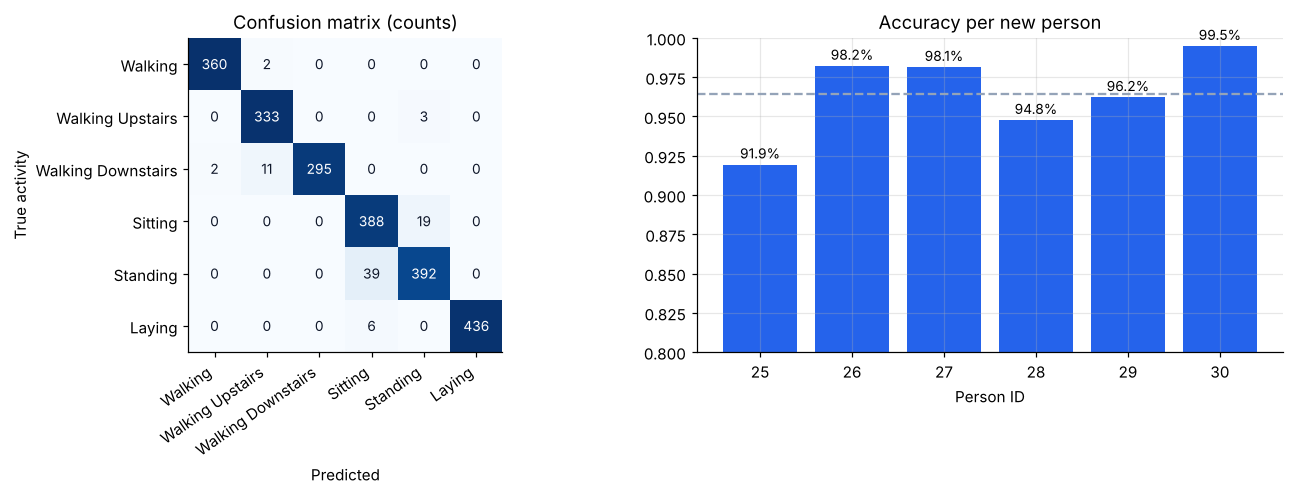

Per-activity F1: {'Walking': 0.994, 'Walking Upstairs': 0.977, 'Walking Downstairs': 0.978, 'Sitting': 0.924, 'Standing': 0.928, 'Laying': 0.993}
Total errors: 82 · largest confusions:
Standing            Sitting             39
Sitting             Standing            19
Walking Downstairs  Walking Upstairs    11
Laying              Sitting              6


In [5]:
p_lr = preds["Logistic Regression"]
cm = confusion_matrix(y_te, p_lr)
rep = classification_report(y_te, p_lr, target_names=ACT, output_dict=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(6):
    for j in range(6):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if i == j else "#0F172A", fontsize=9)
ax[0].set_xticks(range(6), ACT, rotation=35, ha="right"); ax[0].set_yticks(range(6), ACT)
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True activity"); ax[0].set_title("Confusion matrix (counts)"); ax[0].grid(False)

per_user = pd.DataFrame({"Person": g_te, "correct": p_lr == y_te}).groupby("Person").correct.mean()
ax[1].bar(per_user.index.astype(str), per_user.values, color=BLUE)
ax[1].axhline(accuracy_score(y_te, p_lr), ls="--", color=GREY)
ax[1].set_ylim(.8, 1); ax[1].set_title("Accuracy per new person"); ax[1].set_xlabel("Person ID")
for i, v in enumerate(per_user.values):
    ax[1].text(i, v + .004, f"{v:.1%}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

errors = pd.DataFrame(cm, index=ACT, columns=ACT).where(~np.eye(6, dtype=bool)).stack().dropna().astype(int)
print("Per-activity F1:", {a: round(rep[a]["f1-score"], 3) for a in ACT})
print(f"Total errors: {errors.sum()} · largest confusions:")
print(errors.sort_values(ascending=False).head(4).to_string())

- **Walking and lying are recognised almost perfectly** (F1 ≥ 0.99); the stair classes reach ≈0.98.
- **Sitting vs. standing causes most errors** (39 + 19 = 58 of 82). Both are upright, almost motionless postures, so a
  waist-worn sensor sees nearly the same signal. A wrist device, or a rule using posture transitions, is the most promising fix.
- **Quality is consistent across new people** (91.9 %–99.5 %). No customer group falls far behind, but person 25 shows that
  individual movement styles matter, which is another argument for testing with more people before launch.

## 6. Edge trade-offs: how many features does the device need?

On a wearable, the expensive part is often **computing the features** from raw sensor signals (filters, FFTs), not the classifier.
The curve shows grouped cross-validated quality of Logistic Regression for different feature budgets:

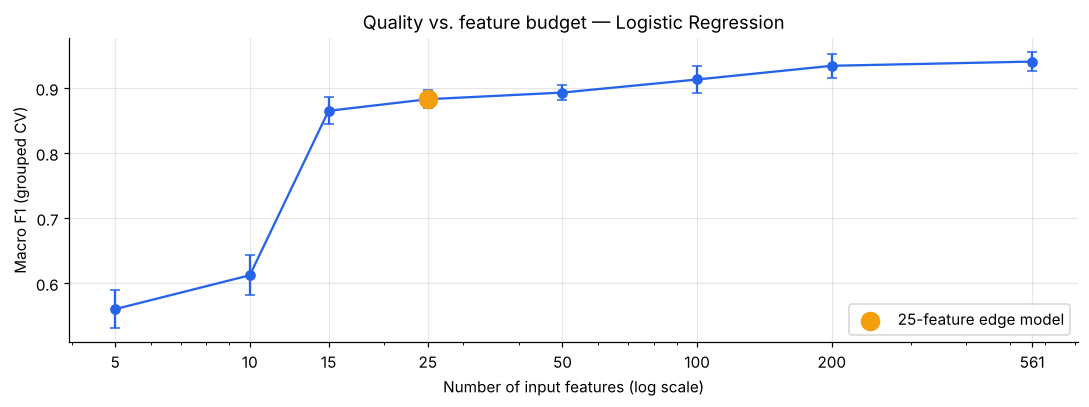

Features,CV Macro F1,std
5,0.560,0.030
10,0.612,0.030
15,0.865,0.021
25,0.883,0.014
50,0.893,0.011
100,0.913,0.020
200,0.934,0.018
561,0.941,0.015


In [6]:
budgets = [5, 10, 15, 25, 50, 100, 200, 561]
curve = pd.DataFrame([(k, *grouped_cv_f1(lr_pipeline, X_tr[:, ranking[:k]], y_tr, g_tr, cv_grouped)) for k in budgets],
                     columns=["Features", "CV Macro F1", "std"])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.errorbar(curve.Features, curve["CV Macro F1"], yerr=curve["std"], marker="o", color=BLUE, capsize=3)
edge = curve[curve.Features == 25]
ax.scatter(edge.Features, edge["CV Macro F1"], s=140, color=AMBER, zorder=3, label="25-feature edge model")
ax.set_xscale("log"); ax.set_xticks(budgets, budgets)
ax.set_xlabel("Number of input features (log scale)"); ax.set_ylabel("Macro F1 (grouped CV)")
ax.set_title("Quality vs. feature budget — Logistic Regression"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
display(curve.style.format({"CV Macro F1": "{:.3f}", "std": "{:.3f}"}).hide(axis="index"))

In [7]:
lr_model = models["Logistic Regression"][0]
native_us = native_lr_latency_us(lr_model, X_te[:1])
ops = X.shape[1] * 6 * 2 + X.shape[1] * 2
print(f"Logistic Regression as plain arithmetic: ~{ops:,} operations, {native_us:.1f} µs per prediction on this CPU")
print(f"Budget per prediction: {2.56 * 0.5:.2f} s  ->  the classifier uses well under 0.1 % of it, even on a CPU 100x slower")

Logistic Regression as plain arithmetic: ~7,854 operations, 5.1 µs per prediction on this CPU
Budget per prediction: 1.28 s  ->  the classifier uses well under 0.1 % of it, even on a CPU 100x slower


- Quality rises steeply up to ~15 features and then flattens: **25 features keep ≈94 % of the full model's cross-validated
  Macro F1** with 95.5 % fewer inputs, and 200 features get within 0.01 of the full set.
- The classifier itself is **negligible**: a few thousand multiply-adds per prediction, microseconds on a laptop CPU, against a
  1.28-second budget. The real on-device cost question is feature extraction, which should be measured on the target hardware.
- **Decision rule:** ship the full model where the device can compute the standard feature set. Fall back to a reduced set only
  if hardware tests show feature extraction is too expensive, and then try 50–200 features before going as low as 25.

*Note: the feature ranking is computed once on all training persons, so the curve is slightly optimistic. The ranking within
each CV fold would be more conservative.*

## 7. Business case: on-device recognition vs. streaming to the cloud

Running the model on the device means only small activity summaries are uploaded instead of raw 50 Hz sensor data. The figures
below use **illustrative assumptions** (adjust them for a real decision; the Streamlit app makes them interactive).

In [8]:
A = dict(devices=100_000, hours_per_day=14, sampling_hz=50, channels=6, bytes_per_value=2,
         usd_per_gb=0.10, usd_per_million_predictions=0.50, summary_bytes_per_minute=64)

def business_case(a):
    secs = a["hours_per_day"] * 3600
    raw_day = a["sampling_hz"] * a["channels"] * a["bytes_per_value"] * secs           # bytes / device / day
    edge_day = a["summary_bytes_per_minute"] * a["hours_per_day"] * 60
    preds_month = secs / 1.28 * a["devices"] * 30
    cloud_data = raw_day * a["devices"] * 30 / 1e9 * a["usd_per_gb"]
    cloud_inference = preds_month / 1e6 * a["usd_per_million_predictions"]
    edge_data = edge_day * a["devices"] * 30 / 1e9 * a["usd_per_gb"]
    return dict(raw_mb_per_device_day=raw_day / 1e6, edge_kb_per_device_day=edge_day / 1e3,
                volume_reduction=1 - edge_day / raw_day, cloud_data_usd=cloud_data,
                cloud_inference_usd=cloud_inference, edge_usd=edge_data,
                saving_usd=cloud_data + cloud_inference - edge_data)

bc = business_case(A)
print(f"Raw upload per device/day: {bc['raw_mb_per_device_day']:.1f} MB  ->  on-device summaries: {bc['edge_kb_per_device_day']:.1f} KB "
      f"({bc['volume_reduction']:.2%} less data)")
print(f"Monthly cloud cost, streaming: ${bc['cloud_data_usd'] + bc['cloud_inference_usd']:,.0f} "
      f"(data ${bc['cloud_data_usd']:,.0f} + inference ${bc['cloud_inference_usd']:,.0f})  vs. on-device: ${bc['edge_usd']:,.0f}")

# Sensitivity: the saving depends mostly on the cloud inference price and on fleet size
sens = pd.DataFrame([{"Devices": f"{d:,}", "Cloud price per 1M predictions": f"${p:.2f}",
                      "Monthly saving (USD)": business_case({**A, "devices": d, "usd_per_million_predictions": p})["saving_usd"]}
                     for d in [10_000, 100_000, 1_000_000] for p in [0.0, 0.10, 0.50]])
display(sens.pivot(index="Devices", columns="Cloud price per 1M predictions", values="Monthly saving (USD)")
        .loc[["10,000", "100,000", "1,000,000"]]
        .style.format("${:,.0f}").set_caption("Estimated monthly cloud saving"))

Raw upload per device/day: 30.2 MB  ->  on-device summaries: 53.8 KB (99.82% less data)
Monthly cloud cost, streaming: $68,134 (data $9,072 + inference $59,062)  vs. on-device: $16


Cloud price per 1M predictions,$0.00,$0.10,$0.50
Devices,,,
"10,000",$906,"$2,087","$6,812"
"100,000","$9,056","$20,868","$68,118"
"1,000,000","$90,559","$208,684","$681,184"


In [9]:
err_full = 1 - accuracy_score(y_te, preds["Logistic Regression"])
err_25 = 1 - accuracy_score(y_te, preds["Logistic Regression (top 25)"])
print(f"Mislabelled time per user per day ({A['hours_per_day']} h worn): "
      f"full model {err_full * A['hours_per_day'] * 60:.0f} min · 25-feature model {err_25 * A['hours_per_day'] * 60:.0f} min "
      f"({err_25 / err_full:.1f}x more)")

Mislabelled time per user per day (14 h worn): full model 30 min · 25-feature model 85 min (2.8x more)


- **Data volume:** on-device recognition removes more than 99 % of the upload volume, regardless of prices. Less radio time
  also typically means longer battery life, though that has to be measured on the device.
- **Cloud cost:** with the default assumptions, streaming would cost tens of thousands of dollars per month at 100k devices, mostly
  for cloud inference. Even if inference were free, ingesting and storing raw data would still cost ≈$9k per month at
  100k devices, and this grows linearly with the fleet.
- **Privacy:** raw motion data never has to leave the device, which reduces data-protection exposure. This is a qualitative
  benefit and not legal advice.
- **User experience:** the full model mislabels about 30 minutes of a 14-hour day, mostly sitting vs. standing. The 25-feature
  model would mislabel about 85 minutes, which is the clearest way to explain the cost of cutting features.

## 8. Recommendation

**Ship Logistic Regression with the full 561-feature set.**

| Criterion | Evidence |
|---|---|
| Quality for new users | Best Macro F1 (0.966) and accuracy (96.4 %); consistent across all six new people |
| Footprint | 25 KB, ~7,900 operations per prediction, negligible against the 1.28 s budget |
| Explainability | One weight per feature and activity, easy to audit and debug |
| Alternatives | LightGBM −2.3 points and ~70× larger; 25-feature model ≈2.8× more errors |

**Trade-off accepted:** the device must compute the full feature set. If hardware tests show this is too expensive, use the
reduced-feature Logistic Regression with the largest feature budget the device can afford.

### Risks and next steps
1. **Evidence base:** only six test people, lab conditions, phone on the waist → run leave-people-out validation over all 30
   people and collect wrist-worn, everyday data before launch.
2. **Feature extraction cost** has not been measured → port the feature pipeline and model to C / TensorFlow Lite Micro and
   measure latency and energy on the target chip.
3. **Sitting vs. standing** → test posture-transition rules or additional sensors; consider merging them into one "stationary"
   class if the product does not need the distinction.
4. **Monitoring** → track prediction confidence and class mix after launch to detect drift.

## Reproducibility

In [10]:
print(f"Python {platform.python_version()} · scikit-learn {sklearn.__version__} · LightGBM {lightgbm.__version__} · "
      f"NumPy {np.__version__} · pandas {pd.__version__}")
print(f"Platform: {platform.platform()} · CPU: {platform.processor() or platform.machine()} · cores: {os.cpu_count()}")
print(f"Random seed: {RANDOM_STATE} · test persons: {TEST_SUBJECTS}")

Python 3.13.16 · scikit-learn 1.9.1 · LightGBM 4.7.0 · NumPy 2.5.3 · pandas 3.0.5
Platform: Linux-6.18.44-fc-v185-x86_64-with-glibc2.39 · CPU: x86_64 · cores: 2
Random seed: 42 · test persons: [25, 26, 27, 28, 29, 30]


Data: Anguita, D., Ghio, A., Oneto, L., Parra, X., & Reyes-Ortiz, J. L. (2013). *Human Activity Recognition Using Smartphones*.
UCI Machine Learning Repository, https://doi.org/10.24432/C54S4K (CC BY 4.0). "EdgeFit" is a fictional company used to frame the case.